[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch25_LabCh25_Linear_Attention.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 25: Linear Attention and Other Ways to Beat n²** (Part V: Attending).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=25](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=25)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch25 - Linear Attention and the n² Bill
## Move the brackets, time the square, watch the softmax lose its sharpness, and turn attention into an RNN

This lab goes with **Chapter 25** of *The Why Book of Deep Learning*.

Full softmax attention compares every token with every other token, so it builds a **T × T** table of scores.
Double the length and the table quadruples. In this lab you build that table, then build a version of attention
that never builds it (**linear attention**, with the feature map elu(x) + 1), and measure what you gain
(time and memory) and what you give up (sharpness). Then you write causal linear attention as a **running sum**,
which is an RNN whose memory is a small matrix, and finish with the **sliding-window** mask used by local attention.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Show that (QKᵀ)V and Q(KᵀV) give the same numbers at very different costs | Steps 2 to 4 |
| Write softmax attention and linear (kernel) attention, both ways round | Steps 5 to 7 |
| Time both as T grows from 256 to 8,192 and find the crossover | Steps 8 to 10 |
| Measure how sharp an attention row is (largest weight, entropy) | Steps 11 to 14 |
| Compute causal linear attention as a running sum and check it against the mask | Steps 15 to 17 |
| Build a sliding-window mask and count what it saves | Steps 18 and 19 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. Wrong predictions you understand
afterwards teach more than right ones you guessed.

> **Runtime:** about a minute on a laptop CPU, NumPy only. The largest array is one 8,192 × 8,192 table of
> 32-bit numbers (268 MB). If your machine is short of memory, delete 8192 from the list in Step 8.

---
# Part A - Moving the brackets

---
## Step 1 - Imports and one seed

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(25)
print("NumPy:", np.__version__)

NumPy: 2.4.6


---
## Step 2 - Two orders of the same product

Forget the softmax for a moment and use the plain dot product as the similarity. Attention without the softmax
is then just three matrices multiplied: **Q Kᵀ V**. Matrix multiplication is associative, so you may put the
brackets where you like:

* **(Q Kᵀ) V**: first the T × T table of scores, then blend the values with it;
* **Q (Kᵀ V)**: first a small d × d summary of all keys and values, then let every query read from it.

> **Predict:** the shapes of `Q @ K.T` and of `K.T @ V` for T = 8 tokens of d = 4 numbers. Will the two final
> answers be equal?

In [2]:
T, d = 8, 4
Q = rng.standard_normal((T, d))
K = rng.standard_normal((T, d))
V = rng.standard_normal((T, d))

left = (Q @ K.T) @ V          # scores first
right = Q @ (K.T @ V)         # summary first
print("Q @ K.T :", (Q @ K.T).shape, "   <- one score per pair of tokens")
print("K.T @ V :", (K.T @ V).shape, "   <- one small summary, whatever T is")
print("final shapes:", left.shape, right.shape)
print("same answer?", np.allclose(left, right), "  largest difference:", np.abs(left - right).max())

Q @ K.T : (8, 8)    <- one score per pair of tokens
K.T @ V : (4, 4)    <- one small summary, whatever T is
final shapes: (8, 4) (8, 4)
same answer? True   largest difference: 2.6645352591003757e-15


---
## Step 3 - Count the multiply-adds

Multiplying an (a × b) matrix by a (b × c) matrix costs a·b·c multiply-adds.

* (Q Kᵀ) V: T·d·T for the scores plus T·T·d for the blend = **2·T²·d**
* Q (Kᵀ V): d·T·d for the summary plus T·d·d for the reads = **2·T·d²**

The ratio is T / d. With d = 64 (a typical head size):

> **Predict:** at what T are the two costs equal? How many times cheaper is the summary-first order at T = 8,192?

In [3]:
d_head = 64
print("     T | scores-first 2*T*T*d | summary-first 2*T*d*d | ratio")
for T_ in (64, 256, 1024, 8192, 100_000):
    a, b = 2 * T_ * T_ * d_head, 2 * T_ * d_head * d_head
    print(f"{T_:6d} | {a:20,} | {b:21,} | {a / b:7.1f}x")

     T | scores-first 2*T*T*d | summary-first 2*T*d*d | ratio
    64 |              524,288 |               524,288 |     1.0x
   256 |            8,388,608 |             2,097,152 |     4.0x
  1024 |          134,217,728 |             8,388,608 |    16.0x
  8192 |        8,589,934,592 |            67,108,864 |   128.0x
100000 |    1,280,000,000,000 |           819,200,000 |  1562.5x


### Why we see this

The two orders cost the same when T = d (here 64). Beyond that, the scores-first order grows with T² and the
summary-first order only with T: at T = 8,192 it is **128 times** cheaper, at 100,000 tokens about 1,560 times.
Nothing was approximated: it is the same product. The catch is that real attention has a **softmax** between
Q Kᵀ and V, and the softmax needs every score of a row before it can divide by their total. That is the only
thing standing between attention and the cheap order.

---
## Step 4 - Why the softmax blocks the trick

Softmax attention uses the similarity exp(q·k). If that similarity could be written as a plain dot product
φ(q)·φ(k) of some **feature map** φ applied to the query and to the key separately, the brackets could move
again. exp(q·k) does not split like that with a short φ. Check one tempting shortcut: exp applied to each
number of q and k separately.

> **Predict:** is exp(q)·exp(k) equal to exp(q·k)?

In [4]:
q, k = rng.standard_normal(d), rng.standard_normal(d)
print("exp(q . k)      =", np.exp(q @ k).round(4))
print("exp(q) . exp(k) =", (np.exp(q) @ np.exp(k)).round(4))

exp(q . k)      = 7.4667
exp(q) . exp(k) = 18.6961


### Why we see this

They are unrelated numbers. exp(q·k) is a perfectly good similarity, but writing it exactly as φ(q)·φ(k) needs a
feature vector with **infinitely** many entries. Two ways out:

* **Linear attention** (Katharopoulos et al., 2020) gives up on softmax and uses a different, simple positive
  feature map, here φ(x) = elu(x) + 1 (x + 1 for positive x, eˣ for negative x: always positive, smooth).
* **Performer** (2020) keeps the softmax as its target and approximates its infinite feature vector with a few
  hundred random features.

---
# Part B - Two attentions, two orders

---
## Step 5 - Softmax attention, the usual way

This is Chapter 22's attention: scores, divide by √d, softmax each row, blend the values. It must build the
T × T table.

In [5]:
def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

def softmax_attention(Q, K, V, mask=None):
    s = Q @ K.T / np.sqrt(Q.shape[-1])
    if mask is not None:
        s = np.where(mask, s, -np.inf)          # masked scores get weight exactly 0
    w = softmax(s)
    return w @ V, w

out_sm, w_sm = softmax_attention(Q, K, V)
print("output", out_sm.shape, "  weights", w_sm.shape, "  row sums", w_sm.sum(1).round(6))

output (8, 4)   weights (8, 8)   row sums [1. 1. 1. 1. 1. 1. 1. 1.]


---
## Step 6 - Linear attention, built the slow way first

Replace exp(q·k) by φ(q)·φ(k) with φ(x) = elu(x) + 1, and normalise each row so its weights sum to 1. Built
this way it still makes a T × T table (we need it to look at the weights later).

> **Predict:** will any weight be zero or negative?

In [6]:
def phi(x):
    return np.where(x > 0, x + 1.0, np.exp(np.minimum(x, 0)))      # elu(x) + 1, always > 0

def linear_attention_quadratic(Q, K, V, mask=None):
    s = phi(Q) @ phi(K).T                    # (T, T) similarities, all positive
    if mask is not None:
        s = s * mask
    w = s / s.sum(axis=1, keepdims=True)     # each row sums to 1
    return w @ V, w

out_lq, w_lq = linear_attention_quadratic(Q, K, V)
print("smallest weight:", w_lq.min().round(4), "  row sums:", w_lq.sum(1).round(6))

smallest weight: 0.0505   row sums: [1. 1. 1. 1. 1. 1. 1. 1.]


---
## Step 7 - Linear attention, the fast way

Now move the brackets. Every query divides by its own total, φ(q)·(sum of all φ(k)), so we keep two summaries:

* **S = φ(K)ᵀ V**, shape (d, d): the keys and values folded together;
* **z = sum of φ(k) over all tokens**, shape (d,): the normaliser.

Each output is then (φ(q) S) / (φ(q) · z). No T × T table anywhere.

> **Predict:** the largest difference from Step 6.

In [7]:
def linear_attention(Q, K, V):
    fq, fk = phi(Q), phi(K)
    S = fk.T @ V                  # (d, d_v)
    z = fk.sum(axis=0)            # (d,)
    return (fq @ S) / (fq @ z)[:, None]

out_lf = linear_attention(Q, K, V)
print("slow way vs fast way, largest difference:", np.abs(out_lf - out_lq).max())
print("summary S:", (phi(K).T @ V).shape, "  normaliser z:", phi(K).sum(0).shape)

slow way vs fast way, largest difference: 2.220446049250313e-16
summary S: (4, 4)   normaliser z: (4,)


### Why we see this

The two linear versions agree to rounding error (about 10⁻¹⁶): the fast one is exact *for linear attention*.
But neither is softmax attention. Linear attention is a **different** attention, not a cheaper way of computing
the same one. Keep that sentence: half the confusion about "efficient attention" comes from forgetting it.

---
# Part C - The bill, measured

---
## Step 8 - Time both and record the largest array

One head, d = 64, 32-bit numbers. For softmax attention the largest array is the T × T table. For linear
attention it is φ(Q), the same size as the input (T × d); the summary S is only 64 × 64. The softmax version
below does its work in place so that only **one** T × T table exists at a time.

> **Predict:** when T doubles, by how much does each time grow? At T = 8,192, how many megabytes is the table?

In [8]:
def softmax_attention_lean(Q, K, V):
    s = Q @ K.T                              # the T x T table (the only big array)
    s *= 1.0 / np.sqrt(Q.shape[-1])
    s -= s.max(axis=1, keepdims=True)
    np.exp(s, out=s)
    s /= s.sum(axis=1, keepdims=True)
    return s @ V

def best_time(fn, *args, repeats=3):
    best = 1e9
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(*args); best = min(best, time.perf_counter() - t0)
    return best

sizes = [256, 512, 1024, 2048, 4096, 8192]
rows = []
print("     T | softmax time | linear time | softmax table | linear largest | x prev (softmax)")
for T_ in sizes:
    q_, k_, v_ = (rng.standard_normal((T_, d_head)).astype("float32") for _ in range(3))
    ts, tl = best_time(softmax_attention_lean, q_, k_, v_), best_time(linear_attention, q_, k_, v_)
    mem_s, mem_l = T_ * T_ * 4 / 1e6, T_ * d_head * 4 / 1e6
    ratio = "" if not rows else f"{ts / rows[-1][1]:5.1f}x"
    rows.append((T_, ts, tl, mem_s, mem_l))
    print(f"{T_:6d} | {ts * 1000:9.1f} ms | {tl * 1000:8.1f} ms | {mem_s:9.1f} MB  | {mem_l:9.2f} MB   | {ratio}")

     T | softmax time | linear time | softmax table | linear largest | x prev (softmax)
   256 |       0.7 ms |      0.3 ms |       0.3 MB  |      0.07 MB   | 
   512 |       1.5 ms |      0.5 ms |       1.0 MB  |      0.13 MB   |   2.2x
  1024 |       4.6 ms |      0.9 ms |       4.2 MB  |      0.26 MB   |   3.1x
  2048 |      23.9 ms |      1.5 ms |      16.8 MB  |      0.52 MB   |   5.2x


  4096 |      87.2 ms |      4.5 ms |      67.1 MB  |      1.05 MB   |   3.7x


  8192 |     358.3 ms |      8.7 ms |     268.4 MB  |      2.10 MB   |   4.1x


---
## Step 9 - Where do they cross?

Below about T = d the two orders cost the same in multiply-adds, but the linear version does extra work (the
feature map, the normaliser) and the softmax version uses one large, efficient matrix product. So at small T the
"slow" method may well be faster.

> **Predict:** below which T, on your machine, does softmax attention win?

In [9]:
for T_ in (16, 32, 64, 128, 256):
    q_, k_, v_ = (rng.standard_normal((T_, d_head)).astype("float32") for _ in range(3))
    ts = best_time(softmax_attention_lean, q_, k_, v_, repeats=50)
    tl = best_time(linear_attention, q_, k_, v_, repeats=50)
    print(f"T = {T_:4d}: softmax {ts * 1e6:7.1f} us, linear {tl * 1e6:7.1f} us  ->  {'softmax' if ts < tl else 'linear'} wins")

T =   16: softmax    20.7 us, linear    34.0 us  ->  softmax wins
T =   32: softmax    26.6 us, linear    44.5 us  ->  softmax wins
T =   64: softmax    48.8 us, linear    61.9 us  ->  softmax wins
T =  128: softmax   177.6 us, linear   133.2 us  ->  linear wins
T =  256: softmax   509.8 us, linear   230.8 us  ->  linear wins


---
## Step 10 - The picture

Log scales on both axes: a straight line of slope 2 is a T² cost, slope 1 is a T cost.

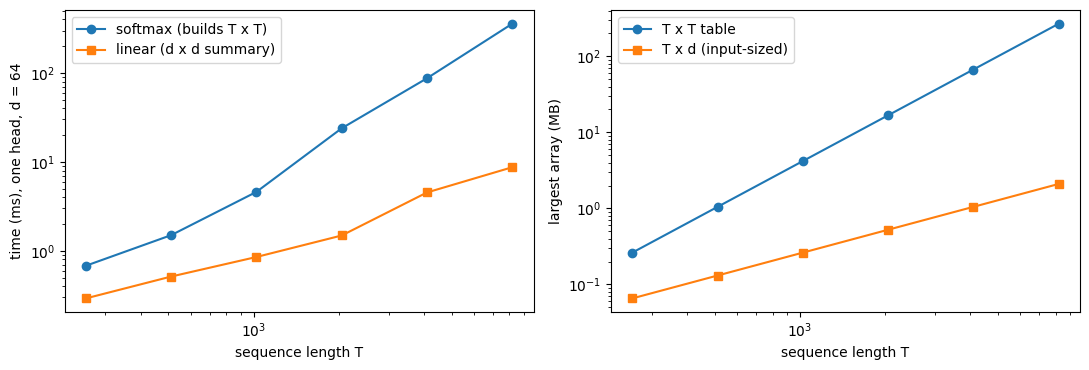

In [10]:
Ts = np.array([r[0] for r in rows])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].loglog(Ts, [r[1] * 1000 for r in rows], "o-", label="softmax (builds T x T)")
ax[0].loglog(Ts, [r[2] * 1000 for r in rows], "s-", label="linear (d x d summary)")
ax[0].set_xlabel("sequence length T"); ax[0].set_ylabel("time (ms), one head, d = 64"); ax[0].legend()
ax[1].loglog(Ts, [r[3] for r in rows], "o-", label="T x T table")
ax[1].loglog(Ts, [r[4] for r in rows], "s-", label="T x d (input-sized)")
ax[1].set_xlabel("sequence length T"); ax[1].set_ylabel("largest array (MB)"); ax[1].legend()
plt.tight_layout(); plt.show()

### Why we see this

The softmax time roughly **quadruples** with every doubling once T is in the thousands, and the table grows
exactly fourfold: 268 MB at T = 8,192 for one head of one layer. The linear time roughly **doubles**, and its
largest array is never bigger than the input itself. At small T the order flips: fixed overheads and the extra
feature-map work make linear attention no faster, often slower (Step 9). Two lessons a benchmark must respect:
measure at the lengths you will really use, and remember that a GPU with a tuned exact kernel (FlashAttention,
Chapter 25) moves the crossover much further out than NumPy on a CPU does. Your times will differ from anyone
else's; the slopes will not.

---
# Part D - What the softmax had that linear attention lacks

---
## Step 11 - A lookup task

The job attention does best is **retrieval**: "find the token that matches me and copy its value". Build that
task directly. 512 keys and values are random. Each query is an exact copy of one key, chosen at random, so the
right answer for query *i* is the value of key `target[i]`.

> **Predict:** how much weight will softmax attention put on the right key? And linear attention? (Uniform
> weight would be 1/512 ≈ 0.002.)

In [11]:
T, d = 512, 64
K = rng.standard_normal((T, d))
V = rng.standard_normal((T, d))
target = rng.permutation(T)
Q = K[target]                                  # query i is a copy of key target[i]

out_sm, w_sm = softmax_attention(Q, K, V)
out_lin, w_lin = linear_attention_quadratic(Q, K, V)
rows_ = np.arange(T)
print(f"mean weight on the right key: softmax {w_sm[rows_, target].mean():.3f}   linear {w_lin[rows_, target].mean():.4f}   uniform {1 / T:.4f}")

mean weight on the right key: softmax 0.716   linear 0.0028   uniform 0.0020


---
## Step 12 - Two sharpness gauges: largest weight and entropy

* **Largest weight in a row**: 1.0 is a hard, one-hot choice; 1/T is a perfectly even spread.
* **Entropy** of a row, in nats: 0 for one-hot, log T for perfectly even (log 512 ≈ 6.24). Read e^entropy as
  "the number of tokens the row is effectively spread over".

> **Predict:** roughly how many tokens is a linear-attention row spread over?

In [12]:
def entropy(w):
    return -(w * np.log(w + 1e-30)).sum(axis=1)

for name, w in (("softmax", w_sm), ("linear ", w_lin)):
    H = entropy(w)
    print(f"{name}: mean largest weight {w.max(1).mean():.4f}   mean entropy {H.mean():.2f} nats"
          f"   (effectively {np.exp(H).mean():6.1f} tokens)")
print(f"perfectly even: entropy {np.log(T):.2f} nats, {T} tokens")

softmax: mean largest weight 0.7163   mean entropy 2.13 nats   (effectively   23.2 tokens)
linear : mean largest weight 0.0029   mean entropy 6.23 nats   (effectively  509.4 tokens)
perfectly even: entropy 6.24 nats, 512 tokens


---
## Step 13 - Did the right value come out?

Compare each output with the value it should have copied (cosine similarity: 1 = same direction, 0 = unrelated),
and count how often the output is closer to the right value than to any other value.

> **Predict:** the share of queries each method retrieves correctly.

In [13]:
def cos_rows(a, b):
    return (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))

for name, o in (("softmax", out_sm), ("linear ", out_lin)):
    nearest = np.argmax(o @ V.T / np.linalg.norm(V, axis=1), axis=1)
    print(f"{name}: cosine with the right value {cos_rows(o, V[target]).mean():.3f}   "
          f"retrieved correctly {np.mean(nearest == target):6.1%}")
print("outputs differ by (relative):", (np.linalg.norm(out_sm - out_lin) / np.linalg.norm(out_sm)).round(3))

softmax: cosine with the right value 0.998   retrieved correctly 100.0%
linear : cosine with the right value 0.064   retrieved correctly   0.8%
outputs differ by (relative): 0.997


### Why we see this

Softmax turns a score lead of a few units into a large weight lead, because it **exponentiates**: e⁸ is about
3,000 times e⁰. So the matching key, whose score is about |k|²/√d ≈ 8 against a typical 0 ± 1, wins most of the
budget and its value comes out nearly intact. Linear attention's similarity φ(q)·φ(k) is a sum of 64 positive
products, so the matching key scores only about 1.4 times as much as a typical other key, not thousands of times more.
With 511 rivals it gets barely more than an even share, and the output is close to the **average** of all
values. Same input, very different answers: this is the blur the chapter talks about, and it is why linear
attention struggles with tasks that need exact recall from a long context.

There is a second, structural reason. The table φ(Q) φ(K)ᵀ is a product of a (T × 64) and a (64 × T) matrix,
so its **rank** is at most 64, however long the sequence. A sharp lookup table for 512 tokens (close to a
permutation) needs rank near 512.

In [14]:
print("rank of the linear-attention table :", np.linalg.matrix_rank(phi(Q) @ phi(K).T))
print("rank of the softmax weight table   :", np.linalg.matrix_rank(w_sm))

rank of the linear-attention table : 64
rank of the softmax weight table   : 512


---
## Step 14 - One row, drawn

A short example (16 tokens, d = 16) so you can see the bars. Query 0 is a copy of key 5.

softmax row: [0.07 0.02 0.01 0.01 0.01 0.72 0.01 0.05 0.01 0.01 0.01 0.01 0.01 0.02
 0.02 0.02]
linear row : [0.08 0.06 0.05 0.06 0.06 0.1  0.06 0.06 0.04 0.06 0.06 0.05 0.05 0.07
 0.07 0.06]


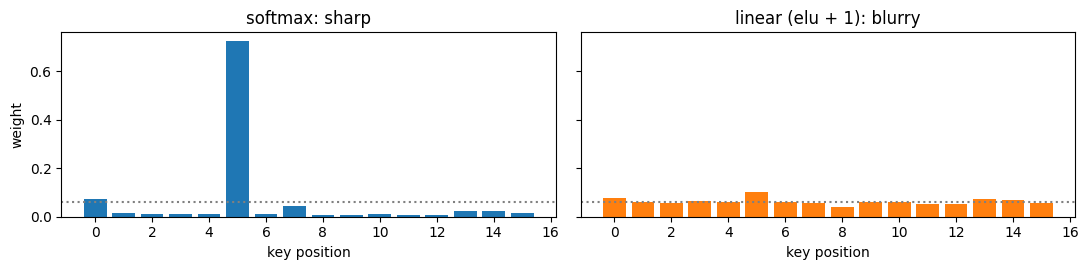

In [15]:
Ts_, ds_ = 16, 16
k16 = rng.standard_normal((Ts_, ds_)); v16 = rng.standard_normal((Ts_, ds_))
q16 = k16[[5]]
_, ws16 = softmax_attention(q16, k16, v16)
_, wl16 = linear_attention_quadratic(q16, k16, v16)
print("softmax row:", ws16[0].round(2))
print("linear row :", wl16[0].round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8), sharey=True)
ax[0].bar(range(Ts_), ws16[0], color="tab:blue"); ax[0].set_title("softmax: sharp")
ax[1].bar(range(Ts_), wl16[0], color="tab:orange"); ax[1].set_title("linear (elu + 1): blurry")
for a in ax:
    a.set_xlabel("key position"); a.axhline(1 / Ts_, ls=":", c="grey")
ax[0].set_ylabel("weight")
plt.tight_layout(); plt.show()

---
# Part E - Causal linear attention is an RNN

---
## Step 15 - The masked version

A text generator must not look at the future. With the causal mask, token *t* may only use tokens 0..*t*.
Here is causal linear attention done the obvious way: build the table, zero the upper triangle, normalise.

> **Predict:** what is the first row of the weights?

In [16]:
T, d = 10, 4
Q = rng.standard_normal((T, d)); K = rng.standard_normal((T, d)); V = rng.standard_normal((T, d))
causal = np.tril(np.ones((T, T)))
out_mask, w_mask = linear_attention_quadratic(Q, K, V, mask=causal)
print("first rows of the causal weights:\n", w_mask[:3, :4])

first rows of the causal weights:
 [[1.    0.    0.    0.   ]
 [0.598 0.402 0.    0.   ]
 [0.174 0.581 0.245 0.   ]]


---
## Step 16 - The same thing as a running sum

With the mask, token *t* needs the sums of φ(k) vᵀ and of φ(k) over tokens 0..*t* only. Those can be **updated**
one token at a time:

* S ← S + φ(kₜ) vₜᵀ   (a d × d matrix: the state)
* z ← z + φ(kₜ)        (a d-vector: the normaliser)
* outputₜ = (φ(qₜ) S) / (φ(qₜ) · z)

That is a recurrent network (Chapter 19) whose hidden state is a **matrix**.

> **Predict:** does the loop give the masked answer exactly? How big is the state after 10 tokens? After 10,000?

In [17]:
S = np.zeros((d, d)); z = np.zeros(d)
out_rnn = np.zeros((T, d))
for t in range(T):
    fk, fq = phi(K[t]), phi(Q[t])
    S += np.outer(fk, V[t])           # write: add this token's key-value pair to the state
    z += fk
    out_rnn[t] = (fq @ S) / (fq @ z)  # read: the query asks the state
print("running sum vs masked table, largest difference:", np.abs(out_rnn - out_mask).max())
print("state size:", S.size + z.size, "numbers, after", T, "tokens, and after any number of tokens")

running sum vs masked table, largest difference: 2.220446049250313e-16
state size: 20 numbers, after 10 tokens, and after any number of tokens


---
## Step 17 - A fixed state versus a growing cache

Softmax attention cannot be folded like this, so a generator keeps every past key and value (the **KV cache**,
Chapter 23) and its memory grows with every token. Compare, per head with d = 64.

> **Predict:** after how many tokens is the KV cache bigger than the linear-attention state?

In [18]:
d_head = 64
state = d_head * d_head + d_head
print(f"linear attention state per head: {state:,} numbers, forever")
for n in (16, 33, 1024, 4096, 100_000):
    cache = 2 * n * d_head
    print(f"  KV cache after {n:7,} tokens: {cache:12,} numbers  ({cache / state:8.1f} x the state)")

linear attention state per head: 4,160 numbers, forever
  KV cache after      16 tokens:        2,048 numbers  (     0.5 x the state)
  KV cache after      33 tokens:        4,224 numbers  (     1.0 x the state)
  KV cache after   1,024 tokens:      131,072 numbers  (    31.5 x the state)
  KV cache after   4,096 tokens:      524,288 numbers  (   126.0 x the state)
  KV cache after 100,000 tokens:   12,800,000 numbers  (  3076.9 x the state)


### Why we see this

The running sum reproduces the masked computation exactly (to rounding): **causal linear attention and a
linear RNN with a matrix state are the same computation**, written two ways. Training can use the parallel
(table or chunked) form; generation can use the loop, at constant cost and constant memory per token. The KV
cache passes the state's size after 33 tokens and is 126 times bigger at 4,096. The price is the same as in
Part D: everything the past said is squeezed into 4,160 numbers per head, and nothing is ever forgotten or
overwritten, so old information blurs into new. Add a learnt *forgetting factor* to the update and you are
standing at the door of Chapter 26 (state-space models).

---
# Part F - Local attention: the sliding window

---
## Step 18 - Build the mask

Another way to beat T²: keep softmax, but let each token look only at the last *w* tokens (itself included).

> **Predict:** how many entries of a 12 × 12 causal window mask with w = 4 are ones?

In [19]:
def sliding_window_mask(T, w):
    i, j = np.arange(T)[:, None], np.arange(T)[None, :]
    return (j <= i) & (j > i - w)

m = sliding_window_mask(12, 4)
for row in m.astype(int):
    print(" ".join("#" if v else "." for v in row))
print("ones:", m.sum(), "of", m.size, "   full causal triangle would have", np.tril(np.ones((12, 12))).sum().astype(int))

# . . . . . . . . . . .
# # . . . . . . . . . .
# # # . . . . . . . . .
# # # # . . . . . . . .
. # # # # . . . . . . .
. . # # # # . . . . . .
. . . # # # # . . . . .
. . . . # # # # . . . .
. . . . . # # # # . . .
. . . . . . # # # # . .
. . . . . . . # # # # .
. . . . . . . . # # # #
ones: 42 of 144    full causal triangle would have 78


---
## Step 19 - Use it, and count the saving at real sizes

> **Predict:** for T = 8,192 and w = 512, what fraction of the full T × T table is computed?

In [20]:
T, d = 12, 8
Q = rng.standard_normal((T, d)); K = rng.standard_normal((T, d)); V = rng.standard_normal((T, d))
_, w_win = softmax_attention(Q, K, V, mask=m)
print("weights outside the window are exactly zero?", np.all(w_win[~m] == 0), "  row sums:", w_win.sum(1).round(6)[:4], "...")

T_big, w_big, layers_ = 8192, 512, 32
entries = sliding_window_mask(T_big, w_big).sum()
print(f"T = {T_big:,}, w = {w_big}: {entries:,} entries of {T_big * T_big:,}  ->  {entries / T_big**2:.1%} of the full table")
print(f"reach after {layers_} layers: about {layers_ * (w_big - 1):,} tokens back")

weights outside the window are exactly zero? True   row sums: [1. 1. 1. 1.] ...


T = 8,192, w = 512: 4,063,488 entries of 67,108,864  ->  6.1% of the full table
reach after 32 layers: about 16,352 tokens back


### Why we see this

The window keeps softmax's sharpness inside the window and costs about T × w instead of T²: 6% of the full
table here, and a KV cache that never needs more than w entries. What it gives up is the **global view**: a token
cannot see anything more than w positions back in one layer. Stacking layers widens the reach (each layer
passes information about w − 1 positions further, like stacked convolutions in Chapter 15), but a fact 10,000
tokens back must survive many relays. That is why real models often mix window layers with a few full-attention
layers or a few "global" tokens that everyone can see.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 3: d = 128 instead of 64 | Where is the crossover in multiply-adds now? | |
| 2 | Step 8: d_head = 16 | Does linear attention get relatively faster or slower? | |
| 3 | Step 11: Q = 3 * K[target] (sharper queries) | Does the softmax get sharper? Does linear attention? | |
| 4 | Step 11: T = 64 instead of 512 | Does linear attention's retrieval improve? Why? | |
| 5 | Step 6: φ(x) = relu(x) instead of elu + 1 | What can go wrong with the normaliser? | |
| 6 | Step 16: multiply S and z by 0.9 before each update | Do outputs still match Step 15? What does the state now favour? | |
| 7 | Step 18: w = 1 | What does each token attend to? | |
| 8 | Step 19: w = 4,096 | What fraction of the table is computed now? | |

---
## Exercises

1. Replace φ by **random features** that approximate exp(q·k) (Performer style): draw a (d × m) matrix W of
   standard normals and use φ(x) = exp(xW − |x|²/2) / √m, after dividing q and k by d^(1/4) (that plays the role of
   the √d). Plot the retrieval accuracy of Step 13 against m from
   16 to 4,096. How large must m be before it approaches softmax, and what does that do to the cost?
2. Write the causal linear attention of Step 16 in **chunks** of 64 tokens: exact (masked) attention inside each
   chunk, the running state between chunks. Check it against Step 15. Why is this form friendlier to GPUs than a
   token-by-token loop?
3. Add one **global token** (position 0) to the sliding-window mask: everyone may see it, and it sees everyone
   before it. How many entries does that add for T = 8,192?
4. In Step 11, measure the time of `softmax_attention` and `linear_attention` at T = 512. Is linear attention's
   speed worth its retrieval accuracy here?
5. Repeat Step 13 with the queries made noisy: Q = K[target] + noise of standard deviation 0.5, 1, 2. Which
   method degrades more gracefully?
6. Show that the rank of the linear-attention table never exceeds the feature size, by trying d = 8, 16, 32 at
   T = 512.

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| Brackets | (QKᵀ)V = Q(KᵀV) for plain dot-product similarity; costs 2T²d vs 2Td² |
| Crossover in multiply-adds | T = d; at T = 8,192, d = 64 the summary order is 128× cheaper |
| What blocks it | softmax: exp(q·k) is not a short φ(q)·φ(k) |
| Linear attention | output = φ(q)S / φ(q)·z with S = φ(K)ᵀV (d × d), z = Σ φ(k); φ = elu + 1 |
| It is not softmax | a different attention, exact for itself, not an approximation of softmax |
| Memory | softmax table T² (268 MB at T = 8,192, float32, one head); linear: input-sized |
| Sharpness | lookup task, T = 512: softmax puts most weight on the right key, linear barely above uniform |
| Rank | linear-attention table has rank ≤ feature size |
| Causal linear attention | S ← S + φ(k)vᵀ, z ← z + φ(k): an RNN with a d × d state (4,160 numbers per head at d = 64) |
| Sliding window | each token sees the last w; cost ≈ T·w; reach grows by about w per layer |